In [ ]:

!pip install librosa soundfile scikit-learn seaborn matplotlib pandas


In [ ]:

import os
import glob
import zipfile
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:
from google.colab import files
import os

uploaded = files.upload()

zip_name = list(uploaded.keys())[0]
print(f"Successfully uploaded: {zip_name}")

Saving zip_path.zip to zip_path.zip
Successfully uploaded: zip_path.zip


In [ ]:
import zipfile

extract_path = "extracted_files"

with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"Files extracted successfully to the '{extract_path}' folder!")

Files extracted successfully to the 'extracted_files' folder!


In [ ]:

audio_files = glob.glob(
    os.path.join(extract_path, "**", "*.wav"),
    recursive=True
)

print("Total audio files:", len(audio_files))
print("\nFirst five files:")

for file in audio_files[:5]:
    print(file)


Total audio files: 1440

First five files:
extracted_files/Actor_06/03-01-01-01-02-01-06.wav
extracted_files/Actor_06/03-01-08-01-02-02-06.wav
extracted_files/Actor_06/03-01-06-01-01-02-06.wav
extracted_files/Actor_06/03-01-08-02-01-02-06.wav
extracted_files/Actor_06/03-01-02-01-02-02-06.wav


In [ ]:

emotion_map = {
    "03": "happy",
    "04": "sad",
    "05": "angry"
}

records = []

for file in audio_files:
    filename = os.path.basename(file)
    parts = filename.split("-")

    if len(parts) >= 3 and parts[2] in emotion_map:
        records.append({
            "file_path": file,
            "emotion": emotion_map[parts[2]]
        })

df = pd.DataFrame(records)

print("Selected recordings:", len(df))
print("\nRecordings per emotion:")
print(df["emotion"].value_counts())


Selected recordings: 576

Recordings per emotion:
emotion
sad      192
happy    192
angry    192
Name: count, dtype: int64


In [ ]:

from IPython.display import Audio, display

sample_path = df.iloc[0]["file_path"]

y, sr = librosa.load(sample_path, sr=22050)

print("Sample file:", sample_path)
print("Sample rate:", sr)
print("Duration:", round(len(y) / sr, 2), "seconds")

display(Audio(y, rate=sr))


Sample file: extracted_files/Actor_06/03-01-04-01-01-02-06.wav
Sample rate: 22050
Duration: 3.6 seconds


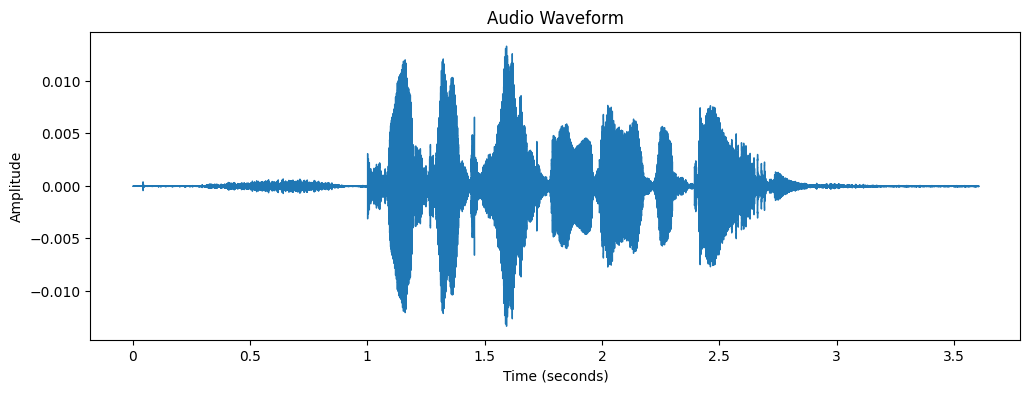

In [ ]:

plt.figure(figsize=(12, 4))

librosa.display.waveshow(y, sr=sr)

plt.title("Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()


MFCC shape: (13, 156)


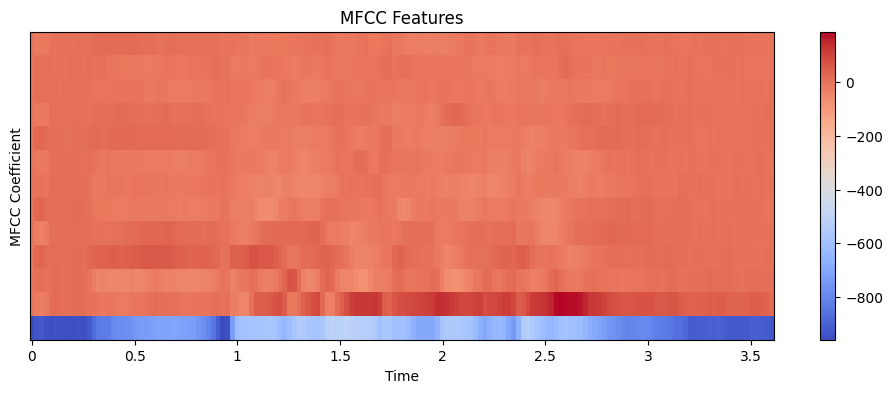

In [ ]:

mfcc = librosa.feature.mfcc(
    y=y,
    sr=sr,
    n_mfcc=13
)

print("MFCC shape:", mfcc.shape)

plt.figure(figsize=(12, 4))

librosa.display.specshow(
    mfcc,
    x_axis="time",
    sr=sr
)

plt.colorbar()
plt.title("MFCC Features")
plt.xlabel("Time")
plt.ylabel("MFCC Coefficient")
plt.show()


In [ ]:

def extract_features(file_path):
    signal, sample_rate = librosa.load(
        file_path,
        sr=22050,
        duration=3
    )

    mfcc_features = librosa.feature.mfcc(
        y=signal,
        sr=sample_rate,
        n_mfcc=13
    )

    return np.mean(mfcc_features, axis=1)

features = extract_features(df.iloc[0]["file_path"])

print("Feature vector:")
print(features)
print("Number of features:", len(features))


Feature vector:
[-6.94163086e+02  5.77421074e+01 -1.42463512e+01  1.71341553e+01
  3.97238994e+00 -1.31851463e+01 -1.58758135e+01 -1.25130196e+01
 -3.09257722e+00 -4.40092385e-01 -8.59788227e+00 -5.53145647e+00
 -2.72326231e+00]
Number of features: 13


In [ ]:

X = []
y_labels = []

for _, row in df.iterrows():
    try:
        feature_vector = extract_features(row["file_path"])
        X.append(feature_vector)
        y_labels.append(row["emotion"])
    except Exception as e:
        print("Could not process:", row["file_path"], e)

X = np.array(X)
y_labels = np.array(y_labels)

print("Feature matrix shape:", X.shape)
print("Label array shape:", y_labels.shape)


Feature matrix shape: (576, 13)
Label array shape: (576,)


In [ ]:

np.save("/content/audio_features.npy", X)
np.save("/content/emotion_labels.npy", y_labels)

print("Features and labels saved successfully!")


Features and labels saved successfully!


In [ ]:

X = []
y_labels = []
groups = []

for _, row in df.iterrows():
    try:
        feature_vector = extract_features(row["file_path"])

        X.append(feature_vector)
        y_labels.append(row["emotion"])
        groups.append(row["actor_id"])

    except Exception as e:
        print("Skipping file:", row["file_path"], e)

X = np.array(X)
y_labels = np.array(y_labels)
groups = np.array(groups)

print("Feature matrix:", X.shape)
print("Labels:", y_labels.shape)
print("Unique actors:", len(np.unique(groups)))


Skipping file: extracted_files/Actor_06/03-01-04-01-01-02-06.wav 'actor_id'
Skipping file: extracted_files/Actor_06/03-01-03-02-01-02-06.wav 'actor_id'
Skipping file: extracted_files/Actor_06/03-01-05-01-02-01-06.wav 'actor_id'
Skipping file: extracted_files/Actor_06/03-01-03-02-02-02-06.wav 'actor_id'
Skipping file: extracted_files/Actor_06/03-01-05-01-01-01-06.wav 'actor_id'
Skipping file: extracted_files/Actor_06/03-01-03-01-02-02-06.wav 'actor_id'
Skipping file: extracted_files/Actor_06/03-01-05-01-01-02-06.wav 'actor_id'
Skipping file: extracted_files/Actor_06/03-01-04-01-01-01-06.wav 'actor_id'
Skipping file: extracted_files/Actor_06/03-01-03-02-01-01-06.wav 'actor_id'
Skipping file: extracted_files/Actor_06/03-01-04-02-02-02-06.wav 'actor_id'
Skipping file: extracted_files/Actor_06/03-01-05-02-01-01-06.wav 'actor_id'
Skipping file: extracted_files/Actor_06/03-01-03-02-02-01-06.wav 'actor_id'
Skipping file: extracted_files/Actor_06/03-01-03-01-02-01-06.wav 'actor_id'
Skipping fil

In [ ]:

import os

extract_path = "/content/extracted_files"

print("Folder exists:", os.path.exists(extract_path))

for root, dirs, files in os.walk(extract_path):
    print("Folder:", root)
    print("WAV files in this folder:",
          sum(f.endswith(".wav") for f in files))

    if root.count(os.sep) - extract_path.count(os.sep) >= 2:
        dirs.clear()


Folder exists: True
Folder: /content/extracted_files
WAV files in this folder: 0
Folder: /content/extracted_files/Actor_06
WAV files in this folder: 60
Folder: /content/extracted_files/Actor_09
WAV files in this folder: 60
Folder: /content/extracted_files/Actor_01
WAV files in this folder: 60
Folder: /content/extracted_files/Actor_03
WAV files in this folder: 60
Folder: /content/extracted_files/Actor_24
WAV files in this folder: 60
Folder: /content/extracted_files/Actor_16
WAV files in this folder: 60
Folder: /content/extracted_files/Actor_22
WAV files in this folder: 60
Folder: /content/extracted_files/Actor_05
WAV files in this folder: 60
Folder: /content/extracted_files/Actor_19
WAV files in this folder: 60
Folder: /content/extracted_files/Actor_18
WAV files in this folder: 60
Folder: /content/extracted_files/Actor_15
WAV files in this folder: 60
Folder: /content/extracted_files/Actor_20
WAV files in this folder: 60
Folder: /content/extracted_files/Actor_21
WAV files in this folder:

In [ ]:

import glob

audio_files = glob.glob(
    "/content/extracted_files/**/*.wav",
    recursive=True
)

print("Total WAV files found:", len(audio_files))
print("First three files:")

for f in audio_files[:3]:
    print(f)


Total WAV files found: 1440
First three files:
/content/extracted_files/Actor_06/03-01-01-01-02-01-06.wav
/content/extracted_files/Actor_06/03-01-08-01-02-02-06.wav
/content/extracted_files/Actor_06/03-01-06-01-01-02-06.wav


In [ ]:

import os
import numpy as np
import librosa

emotion_map = {
    "03": "happy",
    "04": "sad",
    "05": "angry"
}

X = []
y_labels = []
groups = []

for file in audio_files:
    filename = os.path.basename(file)
    parts = filename.split("-")

    if len(parts) != 7:
        continue

    emotion_code = parts[2]

    if emotion_code not in emotion_map:
        continue

    # Actor ID is the final field in the filename
    actor_id = parts[6].replace(".wav", "")

    signal, sr = librosa.load(
        file,
        sr=22050,
        duration=3
    )

    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=sr,
        n_mfcc=13
    )

    X.append(np.mean(mfcc, axis=1))
    y_labels.append(emotion_map[emotion_code])
    groups.append(actor_id)

X = np.array(X)
y_labels = np.array(y_labels)
groups = np.array(groups)

print("Features:", X.shape)
print("Labels:", y_labels.shape)
print("Groups:", groups.shape)
print("Unique actors:", len(np.unique(groups)))


Features: (576, 13)
Labels: (576,)
Groups: (576,)
Unique actors: 24


In [ ]:

from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y_labels, groups=groups)
)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y_labels[train_idx], y_labels[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training actors:", len(set(groups[train_idx])))
print("Testing actors:", len(set(groups[test_idx])))

assert set(groups[train_idx]).isdisjoint(
    set(groups[test_idx])
)

print("Success! Training and testing actors are separate.")


Training samples: 456
Testing samples: 120
Training actors: 19
Testing actors: 5
Success! Training and testing actors are separate.


In [ ]:

from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [ ]:

from sklearn.metrics import accuracy_score, classification_report

y_pred = model.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=["happy", "sad", "angry"],
    zero_division=0
))


Test accuracy: 58.33 %

Classification Report:
              precision    recall  f1-score   support

       happy       0.50      0.30      0.38        40
         sad       0.55      0.75      0.63        40
       angry       0.68      0.70      0.69        40

    accuracy                           0.58       120
   macro avg       0.58      0.58      0.57       120
weighted avg       0.58      0.58      0.57       120



In [ ]:

import pandas as pd
import numpy as np

results = pd.DataFrame({
    "Actual Emotion": y_test[:5],
    "Predicted Emotion": y_pred[:5]
})

print(results)


  Actual Emotion Predicted Emotion
0          happy               sad
1          happy               sad
2            sad               sad
3          angry             angry
4            sad               sad


In [ ]:

import numpy as np
import librosa

def extract_better_features(file_path):
    signal, sr = librosa.load(
        file_path,
        sr=22050,
        duration=3
    )

    # MFCCs: average and variation
    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=sr,
        n_mfcc=20
    )

    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    # Spectral centroid: average brightness
    centroid = librosa.feature.spectral_centroid(
        y=signal, sr=sr
    )
    centroid_mean = np.mean(centroid)
    centroid_std = np.std(centroid)

    # Zero-crossing rate
    zcr = librosa.feature.zero_crossing_rate(signal)
    zcr_mean = np.mean(zcr)
    zcr_std = np.std(zcr)

    # RMS energy: average signal energy
    rms = librosa.feature.rms(y=signal)
    rms_mean = np.mean(rms)
    rms_std = np.std(rms)

    return np.concatenate([
        mfcc_mean,
        mfcc_std,
        [centroid_mean, centroid_std,
         zcr_mean, zcr_std, rms_mean, rms_std]
    ])

print("Improved feature function is ready!")


Improved feature function is ready!


In [ ]:

X_better = []
y_better = []
groups_better = []

for file in audio_files:
    parts = file.split("/")[-1].split("-")

    if len(parts) != 7 or parts[2] not in emotion_map:
        continue

    try:
        X_better.append(extract_better_features(file))
        y_better.append(emotion_map[parts[2]])
        groups_better.append(parts[6].replace(".wav", ""))
    except Exception as e:
        print("Skipped:", file, e)

X_better = np.array(X_better)
y_better = np.array(y_better)
groups_better = np.array(groups_better)

print("Features:", X_better.shape)
print("Labels:", y_better.shape)
print("Actors:", len(np.unique(groups_better)))


Features: (576, 46)
Labels: (576,)
Actors: 24


In [ ]:

from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X_better, y_better, groups=groups_better)
)

X_train_b, X_test_b = X_better[train_idx], X_better[test_idx]
y_train_b, y_test_b = y_better[train_idx], y_better[test_idx]

improved_model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42
)

improved_model.fit(X_train_b, y_train_b)

pred_b = improved_model.predict(X_test_b)

print("Previous accuracy: 58%")
print(
    "New accuracy:",
    f"{accuracy_score(y_test_b, pred_b) * 100:.2f}%"
)

print(classification_report(
    y_test_b,
    pred_b,
    labels=["happy", "sad", "angry"],
    zero_division=0
))


Previous accuracy: 58%
New accuracy: 66.67%
              precision    recall  f1-score   support

       happy       0.57      0.60      0.59        40
         sad       0.64      0.72      0.68        40
       angry       0.82      0.68      0.74        40

    accuracy                           0.67       120
   macro avg       0.68      0.67      0.67       120
weighted avg       0.68      0.67      0.67       120



In [ ]:

import joblib

joblib.dump(
    {
        "model": improved_model,
        "feature_function": extract_better_features,
        "emotions": ["happy", "sad", "angry"]
    },
    "/content/speech_emotion_model.pkl"
)

print("Improved model saved successfully!")


Improved model saved successfully!


In [ ]:

!pip install -q gradio


In [ ]:

import gradio as gr
import numpy as np
import librosa

def predict_emotion(audio_path):
    if audio_path is None:
        return {"No audio provided": 1.0}

    signal, sr = librosa.load(
        audio_path,
        sr=22050,
        duration=3
    )

    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=sr,
        n_mfcc=20
    )

    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    centroid = librosa.feature.spectral_centroid(
        y=signal, sr=sr
    )
    zcr = librosa.feature.zero_crossing_rate(signal)
    rms = librosa.feature.rms(y=signal)

    features = np.concatenate([
        mfcc_mean,
        mfcc_std,
        [
            np.mean(centroid),
            np.std(centroid),
            np.mean(zcr),
            np.std(zcr),
            np.mean(rms),
            np.std(rms)
        ]
    ]).reshape(1, -1)

    probabilities = improved_model.predict_proba(features)[0]

    return {
        emotion: float(probability)
        for emotion, probability
        in zip(improved_model.classes_, probabilities)
    }

demo = gr.Interface(
    fn=predict_emotion,
    inputs=gr.Audio(
        type="filepath",
        label="Upload a voice recording"
    ),
    outputs=gr.Label(
        num_top_classes=3,
        label="Predicted emotion"
    ),
    title="Speech Emotion Recognition",
    description=(
        "Upload a voice recording to estimate whether "
        "the speech sounds happy, sad, or angry. "
        "Predictions are experimental and may be inaccurate."
    )
)

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8d3549baa109ffae43.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
import joblib

model_path = "/content/speech_emotion_model.pkl"

joblib.dump(improved_model, model_path)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download("/content/speech_emotion_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
requirements = """numpy
librosa
scikit-learn
joblib
gradio
soundfile
"""

with open("/content/requirements.txt", "w") as f:
    f.write(requirements)

print("requirements.txt created!")

requirements.txt created!


In [ ]:
files.download("/content/requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

%%writefile /content/app.py

import numpy as np
import librosa
import gradio as gr
import joblib
import os

# Load the trained model
MODEL_PATH = "/content/speech_emotion_model.pkl"

if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(
        "Model file not found. Place speech_emotion_model.pkl beside app.py."
    )

saved_object = joblib.load(MODEL_PATH)

# Support either a model saved directly or a dictionary containing the model
if isinstance(saved_object, dict):
    model = saved_object.get("model", saved_object.get("improved_model"))
    if model is None:
        raise ValueError("The saved file does not contain a recognized model.")
else:
    model = saved_object

# Extract the same 46 features used during training
def extract_features(audio_path):
    signal, sr = librosa.load(
        audio_path,
        sr=22050,
        duration=3
    )

    if len(signal) == 0:
        raise ValueError("The uploaded audio is empty.")

    mfcc = librosa.feature.mfcc(
        y=signal,
        sr=sr,
        n_mfcc=20
    )

    mfcc_mean = np.mean(mfcc, axis=1)
    mfcc_std = np.std(mfcc, axis=1)

    centroid = librosa.feature.spectral_centroid(
        y=signal,
        sr=sr
    )
    zcr = librosa.feature.zero_crossing_rate(signal)
    rms = librosa.feature.rms(y=signal)

    features = np.concatenate([
        mfcc_mean,
        mfcc_std,
        [
            np.mean(centroid),
            np.std(centroid),
            np.mean(zcr),
            np.std(zcr),
            np.mean(rms),
            np.std(rms)
        ]
    ])

    return features.reshape(1, -1)


# Predict emotion from uploaded audio
def predict_emotion(audio_path):
    if audio_path is None:
        return {"No audio provided": 1.0}

    features = extract_features(audio_path)
    probabilities = model.predict_proba(features)[0]

    return {
        str(emotion): float(probability)
        for emotion, probability in zip(
            model.classes_,
            probabilities
        )
    }


# Create the Gradio interface
demo = gr.Interface(
    fn=predict_emotion,
    inputs=gr.Audio(
        type="filepath",
        label="Upload a voice recording"
    ),
    outputs=gr.Label(
        num_top_classes=3,
        label="Predicted emotion"
    ),
    title="Speech Emotion Recognition",
    description=(
        "Upload a voice recording to estimate whether the speech "
        "sounds happy, sad, or angry. This is an experimental model "
        "and predictions may be inaccurate."
    )
)

if __name__ == "__main__":
    demo.launch(share=True)


Overwriting /content/app.py


In [ ]:
import os

print("app.py exists:", os.path.exists("/content/app.py"))
print("Model exists:", os.path.exists("/content/speech_emotion_model.pkl"))

app.py exists: True
Model exists: True


In [ ]:
%cd /content
!python app.py

/content
* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://95efd3e1e0f1bd9fbb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
%cd /content !python app.py
Keyboard interruption in main thread... closing server.
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3957, in block_thread
    time.sleep(0.1)
    ~~~~~~~~~~^^^^^
KeyboardInterrupt

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/content/app.py", line 106, in <module>
    demo.launch(share=True)
    ~~~~~~~~~~~^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/gradio/blocks.py", line 3770, in launch
    self.block_thread()
    ~~~~~~~~~~~~~~~~~^^
  File "/usr/lo